# 03 – Text analytics on NHTSA owner complaints (M4)
Run each cell from top to bottom (Shift + Enter). Outputs are saved to the `outputs/` folder.

## Cell 1 – Settings: check these two file paths

In [1]:
COMPLAINTS_FILE = 'ev_complaints_clean_v1.csv'      # from M2 (for_M4 folder)
LISTINGS_FILE   = 'ev_listings_clean_v1.csv'        # from M1 (shared folder) – needed for Step 7
OUT = 'outputs'

import os, re
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
os.makedirs(OUT, exist_ok=True)
pd.set_option('display.max_colwidth', 120)

## Cell 2 – Load the complaints

In [2]:
c = pd.read_csv(COMPLAINTS_FILE)
print('Complaints loaded:', len(c))                       # expect 9,440
print('Model lines:', c['model_line'].nunique())           # expect 38
c = c[~c['text_missing_flag']].copy()                     # drop blank narratives (expect none)
c['text'] = c['text'].astype(str)
c[['odino', 'make', 'model_line', 'year', 'crash', 'fire', 'component']].head()

Complaints loaded: 9440
Model lines: 38


,odino,make,model_line,year,crash,fire,component
0,10415124,Nissan,Nissan Leaf,2011,N,N,"SERVICE BRAKES, ELECTRIC"
1,10415264,Nissan,Nissan Leaf,2011,Y,N,"SERVICE BRAKES, HYDRAULIC"
2,10415888,Nissan,Nissan Leaf,2011,N,N,"SERVICE BRAKES, HYDRAULIC"
3,10422865,Nissan,Nissan Leaf,2011,N,N,"SERVICE BRAKES, ELECTRIC"
4,10425527,Tesla,Tesla Roadster,2010,N,N,ELECTRICAL SYSTEM|POWER TRAIN


## Cell 3 – Step 1: clean the text
Removes NHTSA staff notes, lower-cases, keeps letters only, removes common words, reduces words to their root.

In [3]:
try:
    import nltk
    from nltk.corpus import stopwords
    from nltk.stem import WordNetLemmatizer
    nltk.download('stopwords', quiet=True); nltk.download('wordnet', quiet=True)
    STOP = set(stopwords.words('english'))
    lem = WordNetLemmatizer().lemmatize
except Exception as e:                                     # fallback if NLTK is not installed
    print('NLTK not available, using scikit-learn stop words and no lemmatising:', e)
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    STOP = set(ENGLISH_STOP_WORDS); lem = lambda w: w

STOP |= {'http', 'https', 'www', 'com', 'vehicle', 'car', 'tesla', 'contact', 'owns', 'stated', 'model', 'nissan', 'chevrolet',
         'chevy', 'ford', 'kia', 'hyundai', 'bmw', 'audi', 'dealer', 'issue', 'problem', 'xxx', 'would', 'also'}
STAFF_NOTES = r'\*[A-Z]{2,3}\b|UPDATED\s*\d{1,2}/\d{1,2}/\d{2,4}|INFORMATION REDACTED PURSUANT TO THE FREEDOM OF INFORMATION ACT \(FOIA\), 5 U\.S\.C\. 552\(B\)\(6\)'

def clean(t):
    t = re.sub(STAFF_NOTES, ' ', t)
    t = re.sub(r'http\S+|www\.\S+', ' ', t)          # web links
    t = re.sub(r'[^a-z\s]', ' ', t.lower())
    return ' '.join(lem(w) for w in t.split() if w not in STOP and len(w) > 2)

c['staff_note'] = c['text'].str.contains(STAFF_NOTES, regex=True)
c['clean_text'] = c['text'].apply(clean)
print('Complaints with staff notes removed: {:.1%}'.format(c['staff_note'].mean()))
c[['text', 'clean_text']].head(3)

Complaints with staff notes removed: 6.5%


,text,clean_text
0,I WAS ACCELERATING AFTER GETTING ON THE FREEWAY HEADING NORTH AND SLIGHTLY UPHILL I MIGHT HAVE BEEN PEAKING AT 55MPH...,accelerating getting freeway heading north slightly uphill might peaking mph truck front suddenly slammed brake hear...
1,I WAS ON THE FREEWAY TRAVELING APPROPRIATELY 65 MPH. THE VEHICLE TO THE RIGHT AND IN FRONT OF ME SUDDENLY SWERVED IN...,freeway traveling appropriately mph right front suddenly swerved lane braked hard front place either side forced bra...
2,"WHEN DRIVING AT 60 MPH DOWN THE FREEWAY, I HIT THE BRAKES HARD TO AVOID A COLLISION WITH THE CAR IN FRONT OF ME. I D...",driving mph freeway hit brake hard avoid collision front decelerated mph veering right avoid hitting inform rapidly ...


## Cell 4 – Step 2: bag-of-words and TF-IDF (top words)

Vocabulary size: 4982


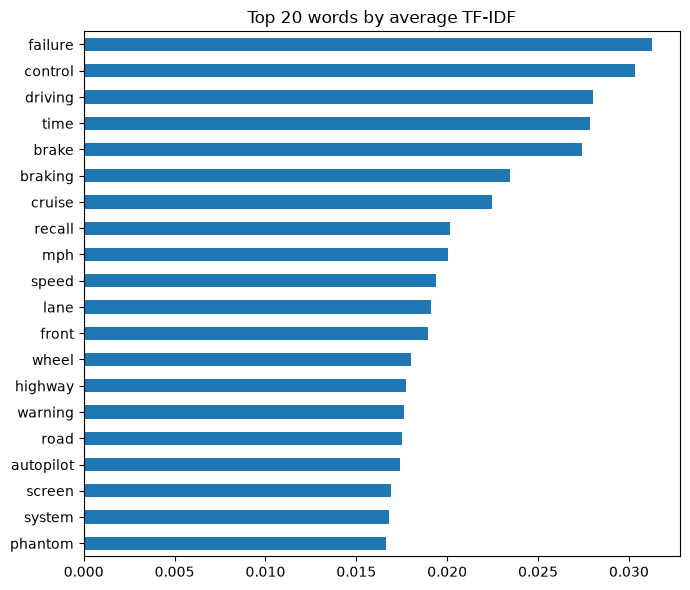

Tesla -> control, failure, driving, cruise, time, braking, brake, autopilot, lane, phantom
Chevrolet -> bolt, recall, battery, fire, part, repair, manufacturer, available, steering, charge
Nissan -> brake, leaf, failure, light, pedal, battery, passenger, stop, seat, airbag


In [6]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
bow = CountVectorizer(min_df=5, max_df=0.8)
Xb = bow.fit_transform(c['clean_text'])
top_bow = pd.Series(np.asarray(Xb.sum(axis=0)).ravel(), index=bow.get_feature_names_out()).nlargest(20)

tfidf = TfidfVectorizer(min_df=5, max_df=0.8)
Xt = tfidf.fit_transform(c['clean_text'])
top_tfidf = pd.Series(np.asarray(Xt.mean(axis=0)).ravel(), index=tfidf.get_feature_names_out()).nlargest(20)
print('Vocabulary size:', len(tfidf.get_feature_names_out()))

ax = top_tfidf.sort_values().plot.barh(figsize=(7, 6), title='Top 20 words by average TF-IDF')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_top_tfidf_words.png', dpi=150); plt.show()

# top words for the three biggest brands
for brand in c['make'].value_counts().index[:3]:
    idx = np.where(c['make'] == brand)[0]
    s = pd.Series(np.asarray(Xt[idx].mean(axis=0)).ravel(), index=tfidf.get_feature_names_out()).nlargest(10)
    print(brand, '->', ', '.join(s.index))

## Cell 5 – Step 3: n-gram analysis (common 2- and 3-word phrases)

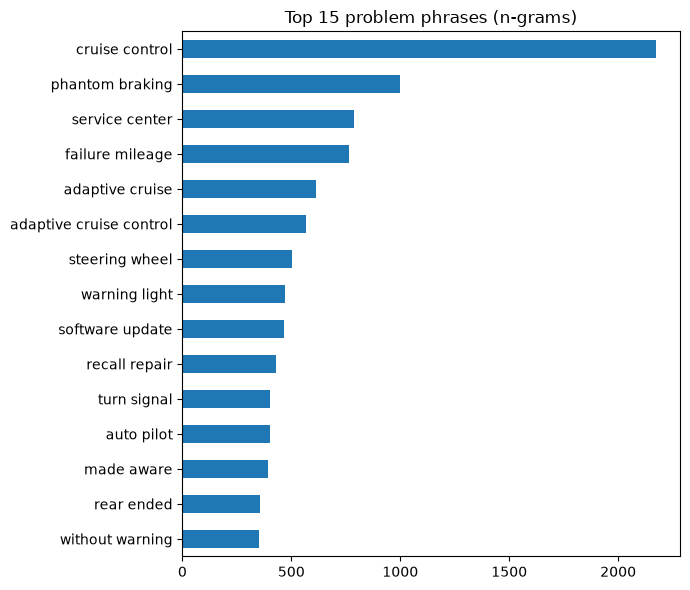

cruise control             2175
phantom braking             998
service center              788
failure mileage             764
adaptive cruise             613
adaptive cruise control     569
steering wheel              501
warning light               473
software update             467
recall repair               430
turn signal                 404
auto pilot                  403
made aware                  395
rear ended                  356
without warning             353
dtype: int64

In [7]:
ng = CountVectorizer(ngram_range=(2, 3), min_df=10)
counts = np.asarray(ng.fit_transform(c['clean_text']).sum(axis=0)).ravel()
phrases = pd.Series(counts, index=ng.get_feature_names_out()).nlargest(15)
ax = phrases.sort_values().plot.barh(figsize=(7, 6), title='Top 15 problem phrases (n-grams)')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_top_ngrams.png', dpi=150); plt.show()
phrases

## Cell 6 – Step 4: sentiment (how negative each complaint is)
VADER score from -1 (very negative) to +1 (very positive). Uses the original text.

count    9440.000000
mean       -0.419427
std         0.524346
min        -0.997900
25%        -0.862500
50%        -0.599400
75%        -0.025800
max         0.993000
Name: sentiment, dtype: float64


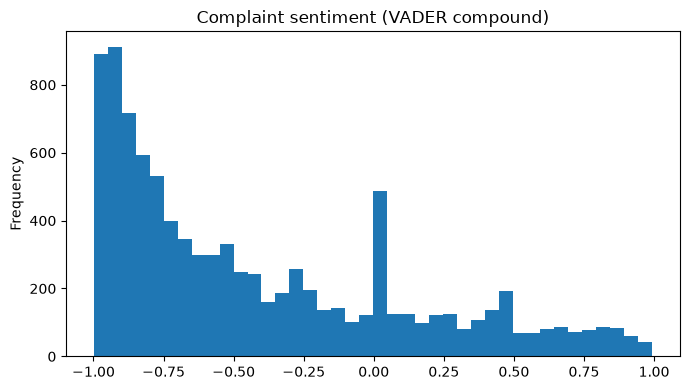

C:\Users\caleb\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 928.73it/s]


Share negative – BERT: 99%, VADER (<0): 76%


In [11]:
try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    c['sentiment'] = c['text'].str.lower().apply(lambda t: sia.polarity_scores(t)['compound'])
except Exception as e:
    print('vaderSentiment not installed – run:  pip install vaderSentiment   then re-run this cell.', e)
    c['sentiment'] = np.nan
print(c['sentiment'].describe())
c['sentiment'].plot.hist(bins=40, figsize=(7, 4), title='Complaint sentiment (VADER compound)')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_sentiment_hist.png', dpi=150); plt.show()

# OPTIONAL comparison with a pre-trained transformer on 300 complaints (needs: pip install transformers torch)
RUN_TRANSFORMER = True
if RUN_TRANSFORMER:
    from transformers import pipeline
    clf = pipeline('sentiment-analysis', model='distilbert-base-uncased-finetuned-sst-2-english', truncation=True)
    sample = c.sample(300, random_state=42)
    res = clf(sample['text'].str.lower().tolist())
    sample['bert_negative'] = [r['label'] == 'NEGATIVE' for r in res]
    print('Share negative – BERT: {:.0%}, VADER (<0): {:.0%}'.format(sample['bert_negative'].mean(), (sample['sentiment'] < 0).mean()))

## Cell 7 – Step 5: tag themes with keyword rules

battery_charging    0.156
braking_assist      0.414
software_screen     0.257
crash_fire          0.105
recall_mention      0.143
dtype: float64


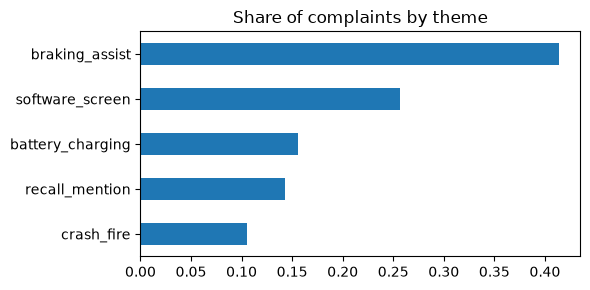

In [12]:
themes = {'battery_charging': r'\bbatter|\brange\b|\bcharg',
          'braking_assist':   r'\bbrak|phantom|collision|autopilot|cruise',
          'software_screen':  r'screen|display|software|update|reboot|touchscreen'}
for k, pat in themes.items():
    c[k] = c['clean_text'].str.contains(pat, regex=True).astype(int)
c['crash_fire'] = ((c['crash'] == 'Y') | (c['fire'] == 'Y')).astype(int)
c['recall_mention'] = c['clean_text'].str.contains(r'\brecall', regex=True).astype(int)
shares = c[list(themes) + ['crash_fire', 'recall_mention']].mean().round(3)
print(shares)
shares.sort_values().plot.barh(figsize=(6, 3), title='Share of complaints by theme')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_theme_shares.png', dpi=150); plt.show()

## Cell 8 – Step 6: check the tags against NHTSA's own part categories

In [13]:
from sklearn.metrics import precision_score, recall_score
truth_rules = {'battery_charging': r'ELECTRICAL SYSTEM|PROPULSION|BATTERY|POWER TRAIN',
               'braking_assist':   r'SERVICE BRAKES|FORWARD COLLISION|LANE DEPARTURE|VEHICLE SPEED CONTROL',
               'software_screen':  r'ELECTRICAL SYSTEM|BACK OVER PREVENTION|VISIBILITY'}
rows = []
for k, pat in truth_rules.items():
    truth = c['component'].fillna('').str.contains(pat, regex=True).astype(int)
    rows.append({'tag': k, 'NHTSA categories used': pat,
                 'precision': round(precision_score(truth, c[k]), 3), 'recall': round(recall_score(truth, c[k]), 3)})
tag_check = pd.DataFrame(rows)
tag_check.to_csv(f'{OUT}/tag_accuracy_check.csv', index=False)
tag_check

,tag,NHTSA categories used,precision,recall
0,battery_charging,ELECTRICAL SYSTEM|PROPULSION|BATTERY|POWER TRAIN,0.731,0.371
1,braking_assist,SERVICE BRAKES|FORWARD COLLISION|LANE DEPARTURE|VEHICLE SPEED CONTROL,0.822,0.844
2,software_screen,ELECTRICAL SYSTEM|BACK OVER PREVENTION|VISIBILITY,0.512,0.440


## Cell 9 – Step 7: summary per make, model line and year  ->  dim_reliability.csv

In [14]:
agg = dict(n_complaints=('odino', 'size'), avg_sentiment=('sentiment', 'mean'),
           battery_charging_share=('battery_charging', 'mean'), braking_assist_share=('braking_assist', 'mean'),
           software_screen_share=('software_screen', 'mean'), crash_fire_share=('crash_fire', 'mean'),
           recall_share=('recall_mention', 'mean'))
SHARE_COLS = ['avg_sentiment', 'battery_charging_share', 'braking_assist_share',
              'software_screen_share', 'crash_fire_share', 'recall_share']

g = c.groupby(['make', 'model_line', 'year']).agg(**agg).reset_index()
line = c.groupby(['make', 'model_line']).agg(**agg).reset_index()

if os.path.exists(LISTINGS_FILE):
    lst = pd.read_csv(LISTINGS_FILE)
    lst = lst.rename(columns={'manufacturer': 'make'})
    n_lst = lst.groupby(['make', 'model_line', 'year']).size().rename('n_listings').reset_index()
    # start from every listed model-year, so model-years with zero complaints are included
    g = n_lst.merge(g, on=['make', 'model_line', 'year'], how='left')
else:
    print('WARNING: listings file not found – complaints_per_listing and zero-complaint rows are skipped.')
    g['n_listings'] = np.nan

g['n_complaints'] = g['n_complaints'].fillna(0).astype(int)
g['complaints_per_listing'] = g['n_complaints'] / g['n_listings']
g['summary_level'] = np.where(g['n_complaints'] >= 10, 'model_year',
                     np.where(g['n_complaints'] > 0, 'model_line', 'none'))

# small samples (1–9 complaints): use the whole model line's shares and sentiment
small = g['summary_level'] == 'model_line'
fill = g.loc[small, ['make', 'model_line']].merge(line, on=['make', 'model_line'], how='left')
g.loc[small, SHARE_COLS] = fill[SHARE_COLS].values
# zero complaints: use the whole model line's values if it has any, otherwise leave blank
zero = g['summary_level'] == 'none'
fillz = g.loc[zero, ['make', 'model_line']].merge(line, on=['make', 'model_line'], how='left')
g.loc[zero, SHARE_COLS] = fillz[SHARE_COLS].values

g = g.round(4)
g.to_csv(f'{OUT}/dim_reliability.csv', index=False)
print(g['summary_level'].value_counts())
if 'n_listings' in g and g['n_listings'].notna().any():
    w = g.groupby('summary_level')['n_listings'].sum() / g['n_listings'].sum()
    print('Share of listings by summary level:\n', w.round(3))
g.head(10)

summary_level
model_year    82
model_line    53
none          24
Name: count, dtype: int64
Share of listings by summary level:
 summary_level
model_line    0.138
model_year    0.833
none          0.029
Name: n_listings, dtype: float64


,make,model_line,year,n_listings,n_complaints,avg_sentiment,battery_charging_share,braking_assist_share,software_screen_share,crash_fire_share,recall_share,complaints_per_listing,summary_level
0,Audi,Audi Q4 e-tron,2022,18,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,none
1,Audi,Audi Q4 e-tron,2023,3,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,none
2,Audi,Audi e-tron,2019,289,26,-0.4384,0.2308,0.3846,0.1923,0.1923,0.0385,0.0900,model_year
3,Audi,Audi e-tron,2020,10,0,-0.4999,0.2391,0.3261,0.2174,0.1304,0.0652,0.0000,none
4,Audi,Audi e-tron,2021,137,13,-0.4954,0.3077,0.1538,0.1538,0.0769,0.0769,0.0949,model_year
5,Audi,Audi e-tron,2022,129,7,-0.4999,0.2391,0.3261,0.2174,0.1304,0.0652,0.0543,model_line
6,Audi,Audi e-tron,2023,11,0,-0.4999,0.2391,0.3261,0.2174,0.1304,0.0652,0.0000,none
7,Audi,Audi e-tron GT,2022,38,6,-0.2893,0.0000,0.1667,0.1667,0.0000,0.0000,0.1579,model_line
8,Audi,Audi e-tron GT,2023,1,0,-0.2893,0.0000,0.1667,0.1667,0.0000,0.0000,0.0000,none
9,BMW,BMW i3,2014,67,35,-0.4055,0.1143,0.1143,0.1429,0.0857,0.0857,0.5224,model_year


## Cell 10 – Extra charts for the slides

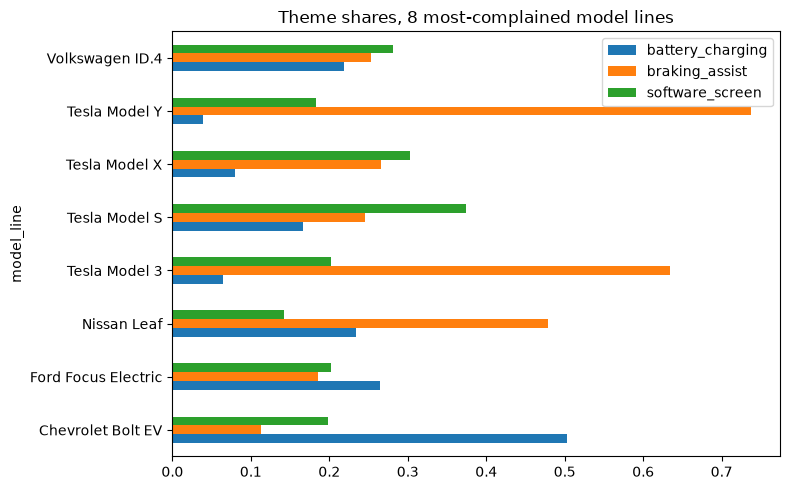

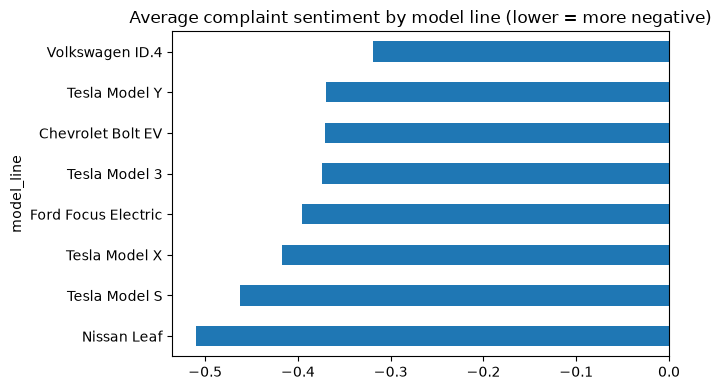

In [15]:
top_lines = c['model_line'].value_counts().index[:8]
by_line = c[c['model_line'].isin(top_lines)].groupby('model_line')[list(themes)].mean()
by_line.plot.barh(figsize=(8, 5), title='Theme shares, 8 most-complained model lines')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_themes_by_model_line.png', dpi=150); plt.show()

sent_line = c[c['model_line'].isin(top_lines)].groupby('model_line')['sentiment'].mean().sort_values()
sent_line.plot.barh(figsize=(7, 4), title='Average complaint sentiment by model line (lower = more negative)')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_sentiment_by_model_line.png', dpi=150); plt.show()

## Cell 11 – Save the tagged complaints and a summary of key numbers

In [16]:
c.drop(columns=['text']).to_csv(f'{OUT}/complaints_tagged.csv', index=False)
summary = {'complaints': len(c), 'model_lines': c['model_line'].nunique(),
           'staff_note_share': round(c['staff_note'].mean(), 3),
           'mean_sentiment': round(c['sentiment'].mean(), 3) if c['sentiment'].notna().any() else None,
           **{f'{k}_share': float(v) for k, v in shares.items()},
           'top_phrases': ', '.join(phrases.index[:5])}
pd.Series(summary).to_csv(f'{OUT}/text_key_numbers.csv')
pd.Series(summary)

complaints                                                                                             9440
model_lines                                                                                              38
staff_note_share                                                                                      0.065
mean_sentiment                                                                                       -0.419
battery_charging_share                                                                                0.156
braking_assist_share                                                                                  0.414
software_screen_share                                                                                 0.257
crash_fire_share                                                                                      0.105
recall_mention_share                                                                                  0.143
top_phrases               cr

In [17]:
g = pd.read_csv(f'{OUT}/dim_reliability.csv')
line_total = g.groupby('model_line')['n_complaints'].transform('sum')
g['complaint_status'] = np.select(
    [g['n_complaints'] >= 10, g['n_complaints'] > 0, line_total > 0],
    ['own_figures', 'model_line_fallback', 'no_complaints_this_year_line_fallback'],
    default='no_complaints_for_model_line')
g.to_csv(f'{OUT}/dim_reliability.csv', index=False)
print(g['complaint_status'].value_counts())

complaint_status
own_figures                              82
model_line_fallback                      53
no_complaints_this_year_line_fallback    14
no_complaints_for_model_line             10
Name: count, dtype: int64
